<a href="https://colab.research.google.com/github/hubertwojcik/deep_learning/blob/main/ann_multilayer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [46]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

# Create the data

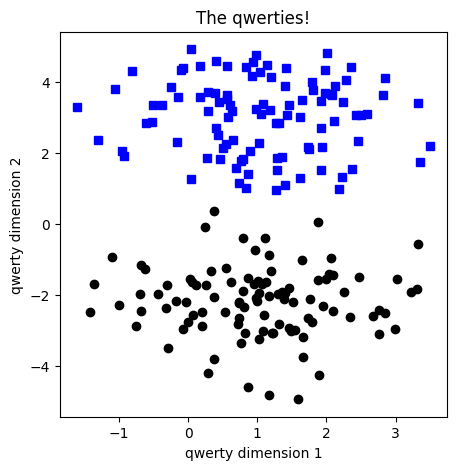

In [47]:
# create data
n_per_clust = 100
blur = 1

A = [ 1, 3]
B= [ 1, -2]

# generate data
a = [ A[0] + np.random.randn(n_per_clust) * blur, A[1] + np.random.randn(n_per_clust) * blur]
b = [B[0] + np.random.randn(n_per_clust) * blur, B[1] + np.random.randn(n_per_clust) * blur]

# true labels
labels_np = np.vstack((np.zeros((n_per_clust,1)), np.ones((n_per_clust, 1))))

#concatate into a trix
data_np = np.hstack((a,b)).T

# convert to a pytorch tensor
data = torch.tensor(data_np).float()
labels = torch.tensor(labels_np).float()

# show the data
fig = plt.figure(figsize=(5,5))
plt.plot(data[np.where(labels==0)[0],0],data[np.where(labels==0)[0],1],'bs')
plt.plot(data[np.where(labels==1)[0],0],data[np.where(labels==1)[0],1],'ko')
plt.title('The qwerties!')
plt.xlabel('qwerty dimension 1')
plt.ylabel('qwerty dimension 2')
plt.show()


# Functions to build and train the model

In [48]:
def create_ann_model(learning_rate):
  ann_classify = nn.Sequential(
      nn.Linear(2,16), # input layer
      nn.ReLU(), # activation layer
      nn.Linear(16,1), # hidden layer
      nn.ReLU(),        # activation layer
      nn.Linear(1,1),   # output unit
      nn.Sigmoid()   # final activation unit
  )

  # loss fun
  loss_fn = nn.BCEWithLogitsLoss()

  # optimizer
  optimizer = torch.optim.SGD(ann_classify.parameters(), lr=learning_rate)

  # model output
  return ann_classify, loss_fn, optimizer

In [49]:
num_epochs = 1000

def train_model(ann_model):
  losses = torch.zeros(num_epochs)

  for epoch in range(num_epochs):
    # forward
    y_hat = ann_model(data)

    # compute loss
    loss = loss_fn(y_hat, labels)
    losses[epoch] = loss

    # backprop
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

  # predictions
  predictions = ann_model(data)

  # compute predictions and report accuracy
  total_acc = 100 * torch.mean(((predictions>.5) == labels).float())
  return losses, predictions, total_acc

# Test the new code by running it once



Final accuracy: 50%


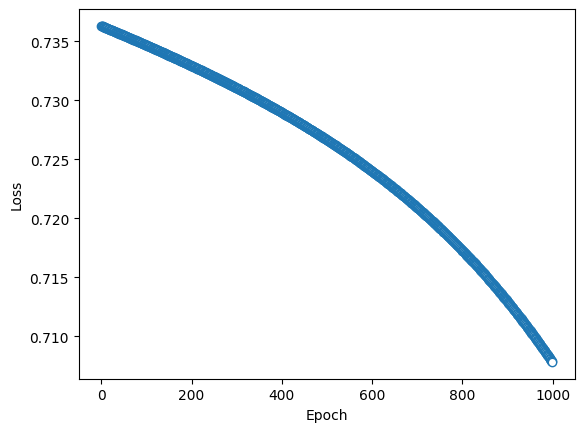

In [50]:
# create
ann_classify, loss_fn, optimizer = create_ann_model(learning_rate=.01)

# run it
losses, predictions, total_acc = train_model(ann_classify)

# report accuracy
print('Final accuracy: %g%%' %total_acc )

# show the losses
plt.plot(losses.detach(),'o', markerfacecolor="w", linewidth=.1)
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.show()

# Experiment

In [54]:
# learning rates
learning_rates = np.linspace(0.001, .1, 50)

# initialize
accuracy_by_learning_rate = []
all_losses = np.zeros((len(learning_rates), num_epochs))

# the loop
for i, learning_rate in enumerate(learning_rates):
  # create and run the model
  ann_classify, loss_fn, optimizer = create_ann_model(learning_rate)
  losses, predictions, total_acc = train_model(ann_classify)

  # save the results
  accuracy_by_learning_rate.append(total_acc)
  all_losses[i,:] = losses.detach()

/tmp/ipykernel_506/175507883.py:16: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments.
  all_losses[i,:] = losses.detach()


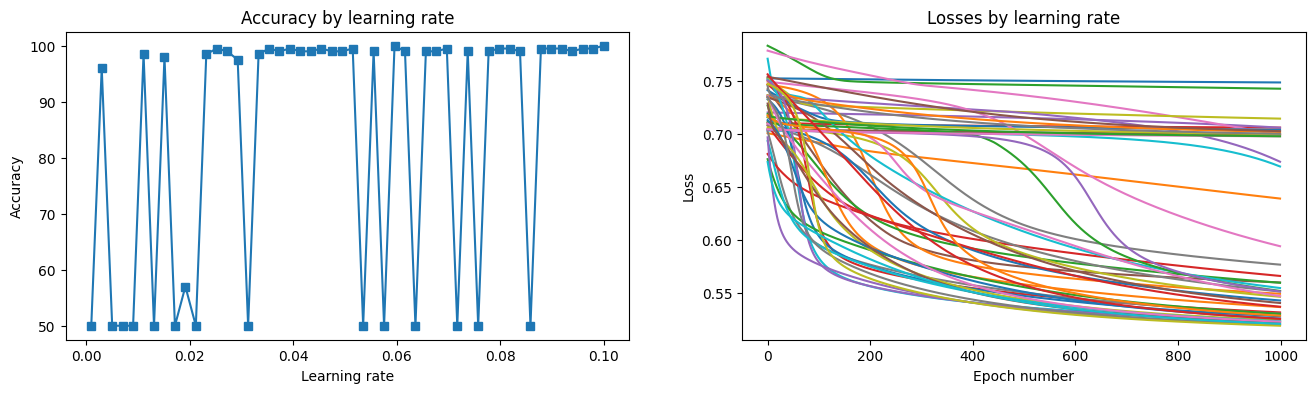

In [55]:
# plot the results
fig,ax = plt.subplots(1,2,figsize=(16,4))

ax[0].plot(learning_rates,accuracy_by_learning_rate,'s-')
ax[0].set_xlabel('Learning rate')
ax[0].set_ylabel('Accuracy')
ax[0].set_title('Accuracy by learning rate')

ax[1].plot(all_losses.T)
ax[1].set_title('Losses by learning rate')
ax[1].set_xlabel('Epoch number')
ax[1].set_ylabel('Loss')
plt.show()